# CIFAR-100 CNN versus FCNN (Master 1)

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 1 SIEC · 2023–2024  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Explore 100-class image classification with neural networks.

**Approach:** Convolutional and fully connected image models.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


<div class="alert alert-success">
    <center><b>University of Ghardaia</b></center>
    <center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 1 SIEC - 2023/2024</i></center>
</div>

------

<br><br>

<center>
    <span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Practical work 4 - AI: CIFAR-100 Deep Classification (Fcnn)  </span></span>
</center>
<br>
</center>

## Guerbouz Mohammed Alaa Eddine

### necessary import

In [10]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical

## Load CIFAR-10 dataset

In [11]:
# Load CIFAR-100 dataset
(train_images, train_labels), (test_images, test_labels) = datasets.cifar100.load_data()

In [12]:
## The shape of X_Train
train_images.shape


(50000, 32, 32, 3)

In [13]:
## The shape of X_test
test_images.shape


(10000, 32, 32, 3)

In [14]:
## The shape of y_train
train_labels.shape


(50000, 1)

### element from the dataset 

[31]


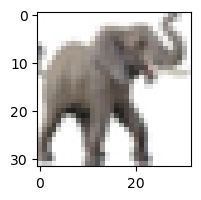

In [15]:
plt.figure(figsize=(15, 2))
plt.imshow(train_images[9])
print(train_labels[9])


## Normalize pixel values to be between 0 and 1

In [18]:
# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0


## build the Cnn model 

In [19]:

fcnn_model = models.Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),  # Flatten the input (image) before passing it to dense layers
    layers.Dense(512, activation='relu'),  # Fully connected layer with 512 units
    layers.Dense(256, activation='relu'),  # Fully connected layer with 256 units
    layers.Dense(100)  # Output layer with 100 units for CIFAR-100 classes
])
# Compile the model
fcnn_model.compile(optimizer='adam',
                   loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                   metrics=['accuracy'])

In [20]:
fcnn_model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 3072)              0         
                                                                 
 dense (Dense)               (None, 512)               1573376   
                                                                 
 dense_1 (Dense)             (None, 256)               131328    
                                                                 
 dense_2 (Dense)             (None, 100)               25700     
                                                                 
Total params: 1730404 (6.60 MB)
Trainable params: 1730404 (6.60 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


## Train the model

In [21]:

# Train the model
history_fcnn = fcnn_model.fit(train_images, train_labels, epochs=10)           


Epoch 1/10
1563/1563 [==============================] - 31s 19ms/step - loss: 4.1735 - accuracy: 0.0616
Epoch 2/10
1563/1563 [==============================] - 32s 20ms/step - loss: 3.8690 - accuracy: 0.0998
Epoch 3/10
1563/1563 [==============================] - 25s 16ms/step - loss: 3.7306 - accuracy: 0.1241
Epoch 4/10
1563/1563 [==============================] - 24s 16ms/step - loss: 3.6221 - accuracy: 0.1452
Epoch 5/10
1563/1563 [==============================] - 25s 16ms/step - loss: 3.5451 - accuracy: 0.1600
Epoch 6/10
1563/1563 [==============================] - 25s 16ms/step - loss: 3.4832 - accuracy: 0.1703
Epoch 7/10
1563/1563 [==============================] - 25s 16ms/step - loss: 3.4337 - accuracy: 0.1798
Epoch 8/10
1563/1563 [==============================] - 24s 16ms/step - loss: 3.3922 - accuracy: 0.1878
Epoch 9/10
1563/1563 [==============================] - 25s 16ms/step - loss: 3.3500 - accuracy: 0.1943
Epoch 10/10
1563/1563 [==============================] - 25s 16m

In [22]:
test_loss_fcnn, test_acc_fcnn = fcnn_model.evaluate(test_images, test_labels, verbose=2)
print(f"Test accuracy (FCNN): {test_acc_fcnn}")
print(f"Loss (FCNN): {test_loss_fcnn}")


313/313 - 1s - loss: 3.4009 - accuracy: 0.1912 - 725ms/epoch - 2ms/step
Test accuracy (FCNN): 0.19120000302791595
Loss (FCNN): 3.400899648666382


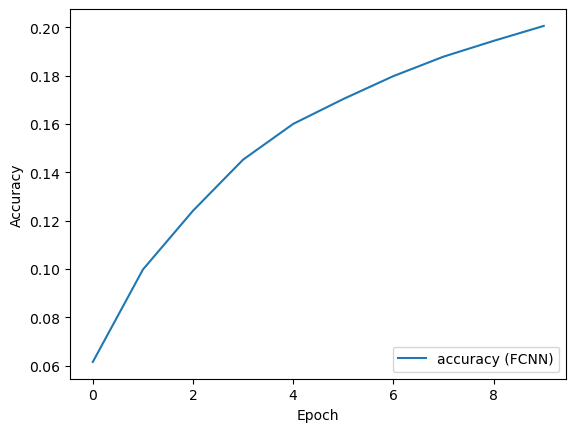

In [23]:
plt.plot(history_fcnn.history['accuracy'], label='accuracy (FCNN)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()


In [25]:
import numpy as np
y_pred_fcnn = fcnn_model.predict(test_images)
y_pred_classes_fcnn = np.argmax(y_pred_fcnn, axis=1)


313/313 [==============================] - 1s 2ms/step


In [28]:

prr = np.argmax(y_pred_fcnn[1])
print(prr)


63


In [30]:
import cv2
from keras.preprocessing.image import img_to_array, load_img
img_fcnn = cv2.imread('testimg.png')
img_fcnn = cv2.resize(img_fcnn, (32, 32))  # Assuming the model expects input images of size 32x32
img_array_fcnn = img_to_array(img_fcnn)
img_array_fcnn = img_array_fcnn / 255.0  # Normalize pixel values to [0, 1]
img_array_fcnn = np.expand_dims(img_array_fcnn, axis=0)

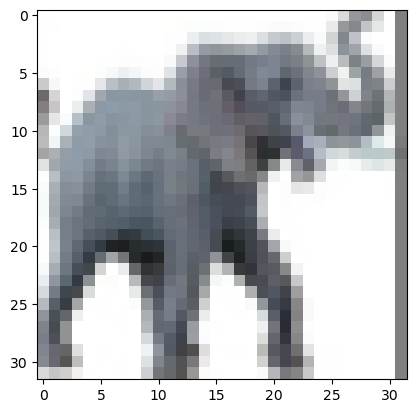

In [32]:

plt.imshow(img_fcnn)

In [33]:
predicted_class_fcnn = np.argmax(fcnn_model.predict(img_array_fcnn)[0])


1/1 [==============================] - 0s 13ms/step


In [37]:
p= fcnn_model.predict(img_array_fcnn)

1/1 [==============================] - 0s 14ms/step


In [38]:
print(np.argmax(p))

20


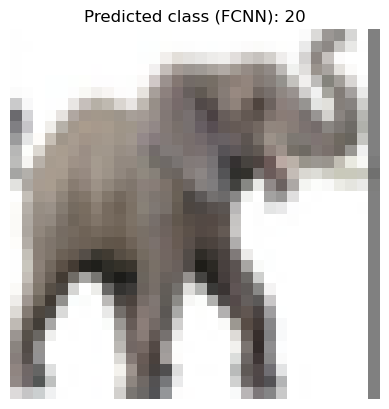

In [39]:

plt.imshow(cv2.cvtColor(img_fcnn, cv2.COLOR_BGR2RGB))
plt.title(f"Predicted class (FCNN): {predicted_class_fcnn}")
plt.axis('off')
plt.show()